<a href="https://colab.research.google.com/github/gitaukennedy/financialperformance_of_BANKS_FDIC/blob/main/financial_banks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/Financial_10_27_2026 (1).csv")

In [ ]:
df.shape

(4288, 161)

In [ ]:
df.isnull().sum()

,0
ZIP,0
IDT1RWAJR,0
EXTRA,9
TFRA,0
IDNCCONR,0
...,...
ESTYMD,0
NONII,9
TRUST,0
EQTOT,9


In [ ]:
print("Missing values:", df.isna().sum().sum())
print("Fully empty columns:", df.isna().all().sum())

Missing values: 86941
Fully empty columns: 8


In [ ]:
burgundy_palette = ["#6D213C", "#A64D68", "#D99AAA", "#E8BBC6", "#F4DDE3"]

sns.set_theme(
    style="whitegrid",
    palette=burgundy_palette,
    rc={
        "figure.figsize": (10, 5),
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False
    }
)

plt.rcParams["axes.prop_cycle"] = plt.cycler(color=burgundy_palette)

In [ ]:
missing = (df.isna().mean().mul(100).sort_values(ascending=False))
display(missing[missing > 0].head(15))

,0
P9LTOT,100.000000
LSALNLS,100.000000
P3LTOT,100.000000
LSASCDBT,100.000000
LSAOA,100.000000
NALTOT,100.000000
LSAORE,100.000000
MSA_NAME,100.000000
LNNDEPC,98.274254
SZLNCON,98.064366


In [ ]:
financial_cols = ["ASSET", "DEP", "NETINC","ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ"]
df[financial_cols].describe().round(2).T


,count,mean,std,min,25%,50%,75%,max
ASSET,4288.0,6124552.36,89010022.47,3490.00,170181.75,384477.50,975237.75,4.016571e+09
DEP,4288.0,4807692.02,66531441.79,0.00,143635.50,327035.50,825104.75,2.787994e+09
NETINC,4279.0,18801.96,283794.46,-131902.00,377.50,1082.00,2991.50,1.397400e+07
ROA,4288.0,1.22,2.40,-38.54,0.76,1.18,1.60,8.143000e+01
ROE,4278.0,10.94,14.33,-385.62,6.98,11.22,15.34,2.115400e+02
NIMY,4288.0,3.88,1.89,-0.50,3.31,3.79,4.30,9.571000e+01
LNLSDEPR,4288.0,76.68,23.10,0.00,65.00,79.38,90.40,5.008800e+02
RBCRWAJ,4288.0,12.19,23.20,0.00,0.00,12.86,16.47,5.067200e+02


In [ ]:
empty_cols = df.columns[df.isna().all()].tolist()
constant_cols = df.columns[df.nunique(dropna=True) <= 1].tolist()
print("Empty columns:", empty_cols)
print("Constant columns:", constant_cols)

Empty columns: ['P9LTOT', 'MSA_NAME', 'NALTOT', 'LSAORE', 'LSALNLS', 'P3LTOT', 'LSAOA', 'LSASCDBT']
Constant columns: ['P9LTOT', 'MSA_NAME', 'NALTOT', 'INSAGNT1', 'LSAORE', 'LSALNLS', 'P3LTOT', 'RISDATE', 'HCTMULT', 'SZLNCRCD', 'LSAOA', 'ACTIVE', 'REPDTE', 'LSASCDBT']


In [ ]:
df.drop(columns=empty_cols)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (4288, 161)


In [ ]:
financial_cols = [ "ASSET", "DEP", "NETINC","ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ"]
df[financial_cols].isna().sum()


,0
ASSET,0
DEP,0
NETINC,9
ROA,0
ROE,10
NIMY,0
LNLSDEPR,0
RBCRWAJ,0


In [ ]:
df[financial_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
ASSET,4288.0,6124552.36,89010022.47,3490.00,24996.97,55611.80,384477.50,7453250.55,65244641.20,4.016571e+09
DEP,4288.0,4807692.02,66531441.79,0.00,14116.94,45316.80,327035.50,5974535.90,53914411.12,2.787994e+09
NETINC,4279.0,18801.96,283794.46,-131902.00,-1388.04,2.90,1082.00,23535.30,196865.88,1.397400e+07
ROA,4288.0,1.22,2.40,-38.54,-2.44,0.00,1.18,2.44,4.01,8.143000e+01
ROE,4278.0,10.94,14.33,-385.62,-22.14,0.12,11.22,23.58,36.79,2.115400e+02
NIMY,4288.0,3.88,1.89,-0.50,1.62,2.51,3.79,5.22,6.72,9.571000e+01
LNLSDEPR,4288.0,76.68,23.10,0.00,6.63,37.61,79.38,105.63,124.88,5.008800e+02
RBCRWAJ,4288.0,12.19,23.20,0.00,0.00,0.00,12.86,29.33,62.72,5.067200e+02


In [ ]:
extreme = df[(df["ROA"].abs() > 10) |(df["ROE"].abs() > 100)]

display(extreme[["NAME", "ASSET", "ROA", "ROE", "NETINC"]].sort_values("ROE", ascending=False))

,NAME,ASSET,ROA,ROE,NETINC
494,FIRST NATIONAL BANK&TRUST CO,383823,1.080207,211.54,1040.0
2359,BANK OF TIOGA,412987,2.617675,194.71,2642.0
3579,CRESCENT BANK,1006087,19.630606,141.04,48518.0
3778,CAPITAL BANK&TRUST CO,226431,81.426739,123.23,42530.0
1540,ENTERPRISE BANK OF SC,522223,8.548876,123.01,10829.0
439,TITAN BANK N A,890741,12.539028,119.38,26812.0
344,MAUCH CHUNK TRUST CO,637949,0.280993,103.05,452.0
2955,CREDIT ONE BANK NA,2161721,28.308559,99.61,146082.0
3857,NORTHWESTERN MUTUAL WEALTH M,521260,38.763591,63.71,47802.0
4194,SQUARE FINL SERVICES INC,1804237,38.767649,63.00,169535.0


In [ ]:
profitability_cols = ["ROA", "ROE", "NIMY", "NETINC"]
profitability = df[profitability_cols].agg(["count", "mean", "median", "std", "min", "max"]).T

display(profitability.round(2))

,count,mean,median,std,min,max
ROA,4288.0,1.22,1.18,2.40,-38.54,81.43
ROE,4278.0,10.94,11.22,14.33,-385.62,211.54
NIMY,4288.0,3.88,3.79,1.89,-0.50,95.71
NETINC,4279.0,18801.96,1082.00,283794.46,-131902.00,13974000.00


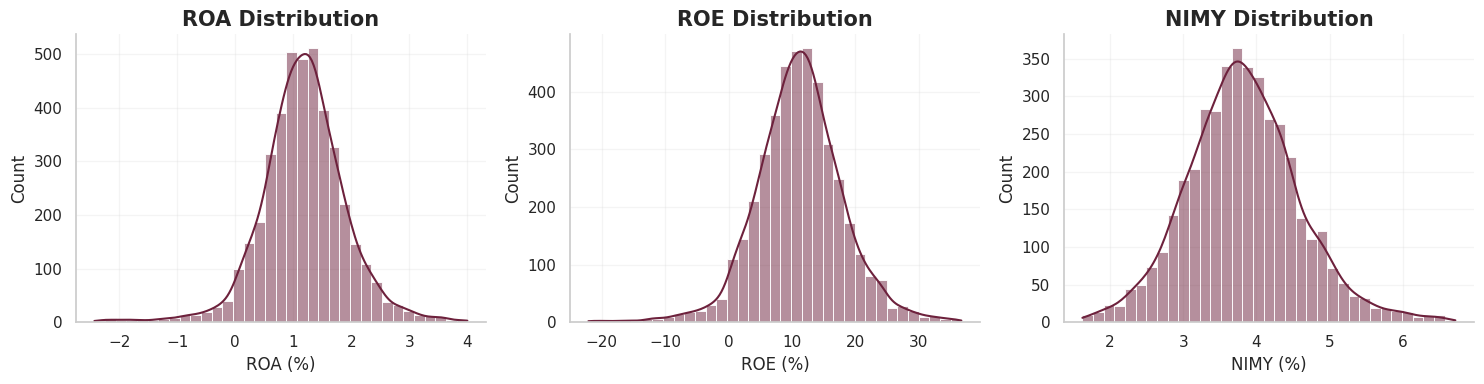

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, profitability_cols):
    values = df[col].dropna()
    lower, upper = values.quantile([0.01, 0.99])
    sns.histplot(values[values.between(lower, upper)],bins=35,kde=True,ax=ax)
    ax.set_title(f"{col} Distribution")
    ax.set_xlabel(f"{col} (%)")

plt.tight_layout()
plt.show()

In [ ]:
df["profit_status"] = np.where(df["ROA"].isna(),"Missing",np.where(df["ROA"] < 0, "Unprofitable", "Profitable"))
profit_counts = df["profit_status"].value_counts()

display(profit_counts)

,count
profit_status,
Profitable,4082
Unprofitable,206


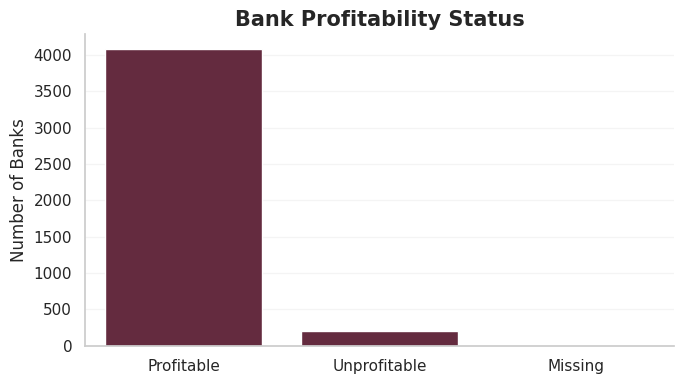

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df,x="profit_status",order=["Profitable", "Unprofitable", "Missing"])

plt.title("Bank Profitability Status")
plt.xlabel("")
plt.ylabel("Number of Banks")
plt.tight_layout()
plt.show()

In [ ]:
large_banks = df[df["ASSET"] >= 1_000_000].copy()
top_roa = (large_banks.sort_values("ROA", ascending=False).head(10))

display(top_roa[["NAME", "STNAME", "ASSET", "ROA", "ROE", "NIMY"]].round(2))

,NAME,STNAME,ASSET,ROA,ROE,NIMY
4194,SQUARE FINL SERVICES INC,UTAH,1804237,38.77,63.00,41.77
2955,CREDIT ONE BANK NA,NEVADA,2161721,28.31,99.61,25.86
3579,CRESCENT BANK,LOUISIANA,1006087,19.63,141.04,7.00
2875,BANK OF NY MELLON TR CO NA,CALIFORNIA,1391736,16.47,20.59,3.76
4046,COLUMN NATIONAL ASSN,CALIFORNIA,1388684,8.28,68.77,9.63
4119,CARTER BANK&TRUST,VIRGINIA,4778484,7.13,77.85,3.15
3103,COMENITY BANK,DELAWARE,7766339,5.25,38.74,22.18
3609,CAPITAL COMMUNITY BANK,UTAH,1504994,5.11,37.13,16.89
3787,JOHN DEERE FINANCIAL FSB,WISCONSIN,4106696,5.09,22.56,6.12
859,SUTTON BANK,OHIO,1683330,5.05,37.14,5.66


In [ ]:
df["ASSETS_B"] = df["ASSET"] / 1_000_000
df["BANK_SIZE"] = pd.cut(
    df["ASSETS_B"],
    bins=[0, 1, 10, 100, np.inf],
    labels=["<$1B", "$1B–$10B", "$10B–$100B", ">$100B"])

df["BANK_SIZE"].value_counts().sort_index()

,count
BANK_SIZE,
<$1B,3234
$1B–$10B,896
$10B–$100B,126
>$100B,32


In [ ]:
size_analysis = (df.groupby("BANK_SIZE", observed=True).agg(
        Banks=("CERT", "count"),
        Median_ROA=("ROA", "median"),
        Median_ROE=("ROE", "median"),
        Median_NIM=("NIMY", "median")).round(2))

display(size_analysis)

,Banks,Median_ROA,Median_ROE,Median_NIM
BANK_SIZE,,,,
<$1B,3234,1.17,11.00,3.86
$1B–$10B,896,1.22,11.84,3.64
$10B–$100B,126,1.19,10.10,3.52
>$100B,32,1.16,12.14,3.11


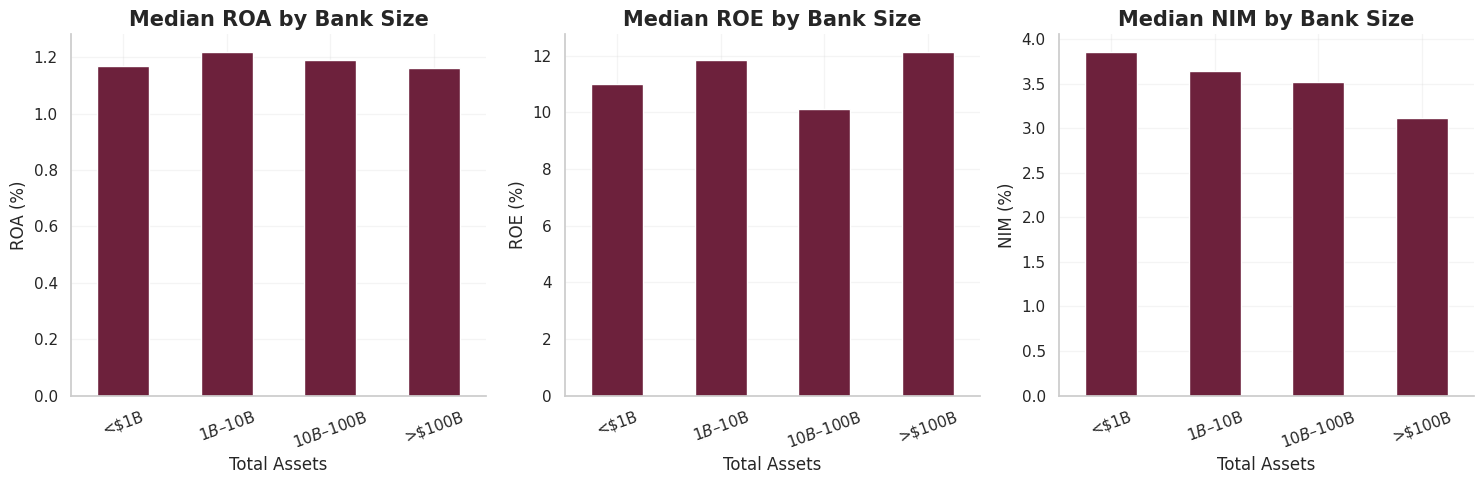

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot Median ROA on the first axis (axes[0])
size_analysis["Median_ROA"].plot(
    kind="bar",
    ax=axes[0],
    title="Median ROA by Bank Size"
)

# Plot Median ROE on the second axis (axes[1])
size_analysis["Median_ROE"].plot(
    kind="bar",
    ax=axes[1],
    title="Median ROE by Bank Size"
)

# Plot Median NIM on the third axis (axes[2])
size_analysis["Median_NIM"].plot(
    kind="bar",
    ax=axes[2],
    title="Median NIM by Bank Size"
)

axes[0].set_ylabel("ROA (%)")
axes[1].set_ylabel("ROE (%)")
axes[2].set_ylabel("NIM (%)")

for ax in axes:
    ax.set_xlabel("Total Assets")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

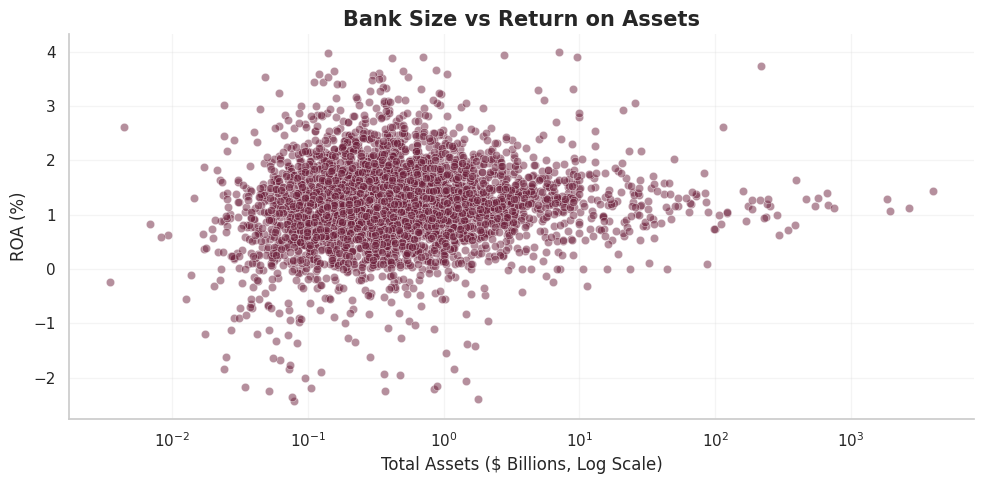

In [ ]:
plot_df = df[(df["ASSET"] > 0) &df["ROA"].notna()].copy()
lower, upper = plot_df["ROA"].quantile([0.01, 0.99])

plot_df = plot_df[plot_df["ROA"].between(lower, upper)]
plt.figure(figsize=(10, 5))

sns.scatterplot(data=plot_df,x="ASSETS_B",y="ROA",alpha=0.5)

plt.xscale("log")
plt.title("Bank Size vs Return on Assets")
plt.xlabel("Total Assets ($ Billions, Log Scale)")
plt.ylabel("ROA (%)")
plt.tight_layout()
plt.show()

In [ ]:
correlation = df[["ASSETS_B", "ROA", "ROE", "NIMY"]].corr(method="spearman")

display(correlation.round(3))

,ASSETS_B,ROA,ROE,NIMY
ASSETS_B,1.000,0.107,0.153,-0.114
ROA,0.107,1.000,0.858,0.469
ROE,0.153,0.858,1.000,0.355
NIMY,-0.114,0.469,0.355,1.000


In [ ]:
risk_cols = ["LNLSDEPR", "RBCRWAJ"]

display( df[risk_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2).T)

,count,mean,std,min,1%,25%,50%,75%,99%,max
LNLSDEPR,4288.0,76.68,23.1,0.0,6.63,65.0,79.38,90.40,124.88,500.88
RBCRWAJ,4288.0,12.19,23.2,0.0,0.00,0.0,12.86,16.47,62.72,506.72


In [ ]:
print("Zero capital ratios:", (df["RBCRWAJ"] == 0).sum())
print("Negative capital ratios:", (df["RBCRWAJ"] < 0).sum())
print("Zero deposits:", (df["DEP"] == 0).sum())

Zero capital ratios: 1741
Negative capital ratios: 0
Zero deposits: 1


In [ ]:
zero_capital = df[df["RBCRWAJ"] == 0]

display(zero_capital[["NAME", "ASSET", "DEP", "ROA", "RBCRWAJ"]].head(15))

,NAME,ASSET,DEP,ROA,RBCRWAJ
3,PHENIX-GIRARD BANK,343760,327418,0.800989,0.0
4,BANK OF EVERGREEN,76245,67039,0.526182,0.0
5,COMMUNITY SPIRIT BANK,225114,202916,1.280629,0.0
6,BANK OF VERNON,427698,356502,1.862594,0.0
7,CITIZENS BANK OF WINFIELD,293444,219430,0.487033,0.0
8,EXCHANGE BANK OF ALABAMA,395319,340899,1.177457,0.0
10,PEOPLES EXCHANGE BANK,97694,85781,0.817458,0.0
11,CENTRAL STATE BANK,778338,698856,1.927805,0.0
12,BANKSOUTH,217918,175462,1.273139,0.0
13,WARREN BANK&TRUST CO,144342,118972,0.829846,0.0


In [ ]:
display(df.assign(Zero_Capital=df["RBCRWAJ"].eq(0)).groupby("BANK_SIZE", observed=True)["Zero_Capital"].agg(["sum", "mean"]).round(3))

,sum,mean
BANK_SIZE,,
<$1B,1539,0.476
$1B–$10B,198,0.221
$10B–$100B,4,0.032
>$100B,0,0.000


In [ ]:
df["RBCRWAJ_REVIEWED"] = df["RBCRWAJ"].replace(0, np.nan)

print("Original median:", df["RBCRWAJ"].median())
print("Excluding zeros:", df["RBCRWAJ_REVIEWED"].median())

Original median: 12.85813709920921
Excluding zeros: 15.654479158951313


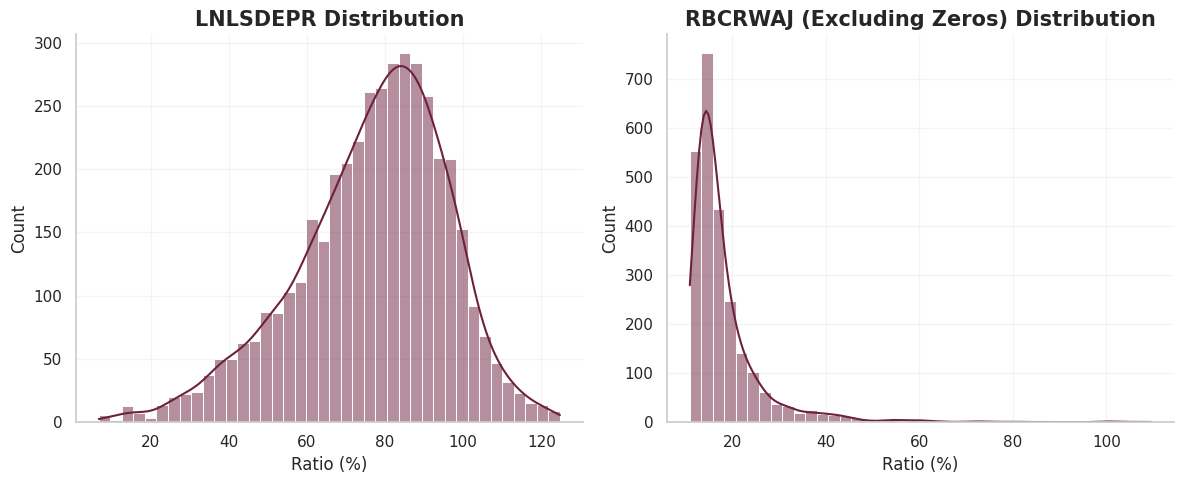

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# We will use the reviewed RBCRWAJ to exclude zero anomalies from the distribution plot
plotting_cols = ["LNLSDEPR", "RBCRWAJ_REVIEWED"]

for ax, col in zip(axes, plotting_cols):
    values = df[col].dropna()
    lower, upper = values.quantile([0.01, 0.99])

    sns.histplot(
        values[values.between(lower, upper)],
        bins=40,
        kde=True,
        ax=ax
    )

    clean_title = "RBCRWAJ (Excluding Zeros)" if col == "RBCRWAJ_REVIEWED" else col
    ax.set_title(f"{clean_title} Distribution")
    ax.set_xlabel("Ratio (%)")

plt.tight_layout()
plt.show()

In [ ]:
risk_by_size = df.groupby("BANK_SIZE", observed=True).agg(Banks=("CERT", "count"),
                                                          Median_Loan_Deposit=("LNLSDEPR", "median"), Median_Capital=("RBCRWAJ_REVIEWED", "median")).round(2)

display(risk_by_size)

,Banks,Median_Loan_Deposit,Median_Capital
BANK_SIZE,,,
<$1B,3234,76.49,16.47
$1B–$10B,896,86.30,14.58
$10B–$100B,126,84.79,14.31
>$100B,32,71.93,14.57


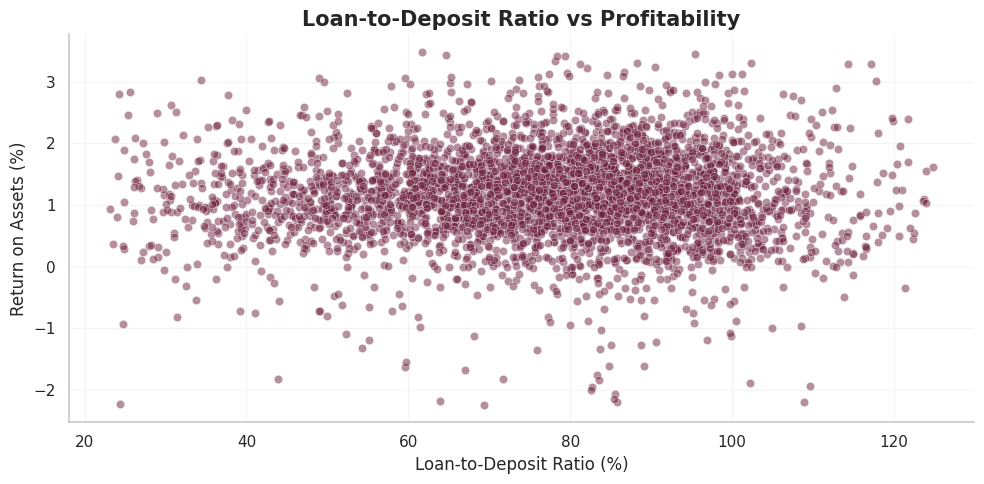

In [ ]:
plot_risk = df[(df["LNLSDEPR"] > 0) &df["ROA"].notna()].copy()

x_low, x_high = plot_risk["LNLSDEPR"].quantile([0.01, 0.99])
y_low, y_high = plot_risk["ROA"].quantile([0.01, 0.99])

plot_risk = plot_risk[plot_risk["LNLSDEPR"].between(x_low, x_high) &plot_risk["ROA"].between(y_low, y_high)]

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=plot_risk,
    x="LNLSDEPR",
    y="ROA",
    alpha=0.5)

plt.title("Loan-to-Deposit Ratio vs Profitability")
plt.xlabel("Loan-to-Deposit Ratio (%)")
plt.ylabel("Return on Assets (%)")
plt.tight_layout()
plt.show()

In [ ]:
df["RBCRWAJ_REVIEWED"] = df["RBCRWAJ"].replace(0, np.nan)

risk_metrics = ["ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ_REVIEWED"]

corr_reviewed = df[risk_metrics].corr(method="spearman")

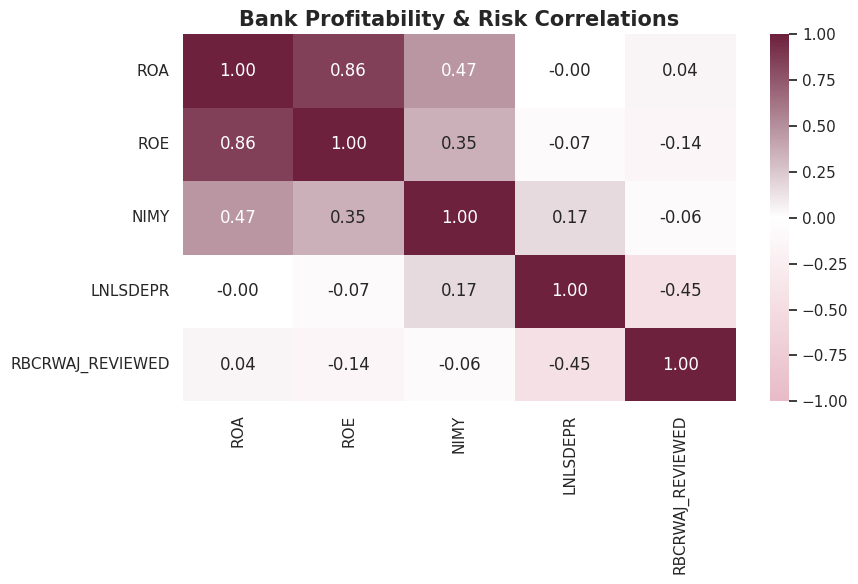

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

burgundy_cmap = LinearSegmentedColormap.from_list(
    "burgundy",
    ["#E8BBC6", "#FFFFFF", "#6D213C"])

plt.figure(figsize=(9, 6))

sns.heatmap(corr_reviewed, annot=True, fmt=".2f", cmap=burgundy_cmap, center=0, vmin=-1, vmax=1)

plt.title("Bank Profitability & Risk Correlations")
plt.tight_layout()
plt.show()

In [ ]:
pairs = (corr_reviewed.where(np.triu(np.ones(corr_reviewed.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False))

display(pairs)

ROA       ROE                 0.857936
          NIMY                0.468926
LNLSDEPR  RBCRWAJ_REVIEWED   -0.445523
ROE       NIMY                0.354554
NIMY      LNLSDEPR            0.165814
ROE       RBCRWAJ_REVIEWED   -0.142904
          LNLSDEPR           -0.068281
NIMY      RBCRWAJ_REVIEWED   -0.063153
ROA       RBCRWAJ_REVIEWED    0.041674
          LNLSDEPR           -0.002632
dtype: float64

In [ ]:
risk_metrics = ["ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ_REVIEWED"]

corr_reviewed = df[risk_metrics].corr(method="spearman")

display(corr_reviewed.round(3))

,ROA,ROE,NIMY,LNLSDEPR,RBCRWAJ_REVIEWED
ROA,1.000,0.858,0.469,-0.003,0.042
ROE,0.858,1.000,0.355,-0.068,-0.143
NIMY,0.469,0.355,1.000,0.166,-0.063
LNLSDEPR,-0.003,-0.068,0.166,1.000,-0.446
RBCRWAJ_REVIEWED,0.042,-0.143,-0.063,-0.446,1.000


In [ ]:
summary = df.groupby("BANK_SIZE", observed=True).agg(Banks=("CERT", "count"), Median_ROA=("ROA", "median"), Median_ROE=("ROE", "median"), Median_NIM=("NIMY", "median"),
                                                     Loan_Deposit=("LNLSDEPR", "median"), Capital_Ratio=("RBCRWAJ", "median")).round(2)

display(summary)

,Banks,Median_ROA,Median_ROE,Median_NIM,Loan_Deposit,Capital_Ratio
BANK_SIZE,,,,,,
<$1B,3234,1.17,11.00,3.86,76.49,11.56
$1B–$10B,896,1.22,11.84,3.64,86.30,13.79
$10B–$100B,126,1.19,10.10,3.52,84.79,14.22
>$100B,32,1.16,12.14,3.11,71.93,14.57


In [ ]:
print("Highest median ROA:", summary["Median_ROA"].idxmax())
print("Lowest median ROA:", summary["Median_ROA"].idxmin())
print("Highest median ROE:", summary["Median_ROE"].idxmax())
print("Highest median capital ratio:", summary["Capital_Ratio"].idxmax())

Highest median ROA: $1B–$10B
Lowest median ROA: >$100B
Highest median ROE: >$100B
Highest median capital ratio: >$100B


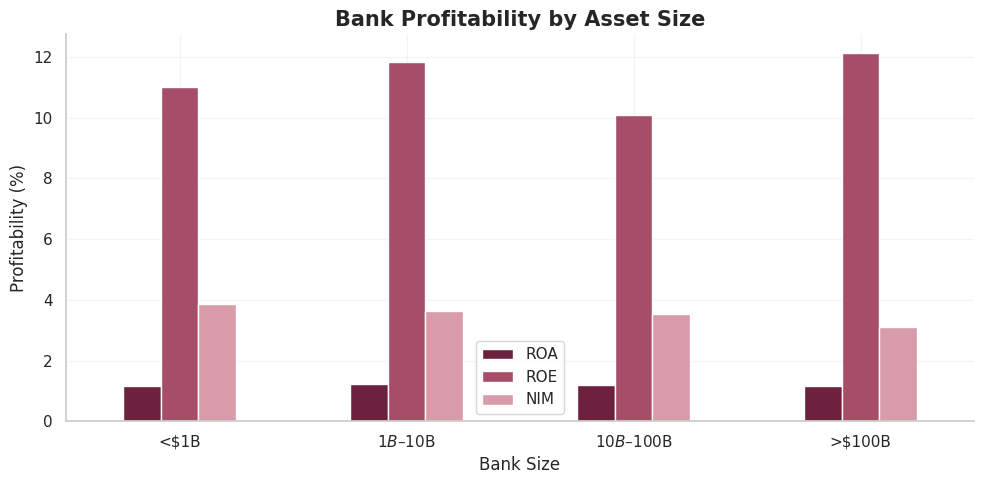

In [ ]:
comparison = summary[["Median_ROA", "Median_ROE", "Median_NIM"]]

comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Bank Profitability by Asset Size")
plt.xlabel("Bank Size")
plt.ylabel("Profitability (%)")
plt.xticks(rotation=0)
plt.legend(["ROA", "ROE", "NIM"])
plt.tight_layout()
plt.show()

In [ ]:
print(f"Total banks analyzed: {len(df):,}")
print(f"Median ROA: {df['ROA'].median():.2f}%")
print(f"Median ROE: {df['ROE'].median():.2f}%")
print(f"Median NIM: {df['NIMY'].median():.2f}%")
print(f"Banks with negative ROA: {(df['ROA'] < 0).sum():,}")
print(f"Most profitable size group by median ROA: {summary['Median_ROA'].idxmax()}")

Total banks analyzed: 4,288
Median ROA: 1.18%
Median ROE: 11.22%
Median NIM: 3.79%
Banks with negative ROA: 206
Most profitable size group by median ROA: $1B–$10B


### Executive Summary: Key Analytical Insights
An empirical evaluation of the 4,288 financial institutions reveals a distinct, non-linear trade-off between bank asset scale, profitability, and balance-sheet risk. While mid-sized institutions ($1B–$10B in assets) operate with the highest asset-utilization efficiency, posting a peak median Return on Assets (ROA) of 1.22%, the largest systemically important banks (>$100B) leverage their massive scale to secure the highest return on equity (median ROE of 12.14%) despite absorbing lower net interest margins (median NIM of 3.11%). Furthermore, correlation analysis exposes structural risk dynamics, highlighting a strong negative correlation (-0.45) between aggressive loan-to-deposit ratios and capital reserves, as well as a prevalent reporting anomaly where 40.6% of institutions (principally under $1B) exhibit zero-capital ratios (`RBCRWAJ`) that require careful treatment to prevent downward bias in risk benchmarking.